# 06 · Final evaluation and explainability

Phase 6 of the reimplementation of Indian Patent No. 601763. Everything here is read from `results/` written by `scripts/phase6_final.py`, which refits every model under one protocol:

- 5-fold stratified CV on the 736 training rows, every statistic refitted inside the fold;
- one fit on all training rows, scored on the 184 held-out rows with 2,000-sample bootstrap 95% confidence intervals;
- paired bootstrap differences against the best baseline (random forest), on the same resampled rows;
- per-hospital metrics on out-of-fold predictions (the hospital is never a feature).

The improvement round before this phase added a **pairwise rule layer** (two-antecedent rules over the three highest-weight attributes). The main fuzzy model was chosen by CV macro F1 on the training split only, as decided in advance; both variants are reported.

In [1]:
import sys, json
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
from IPython.display import Image
pd.set_option("display.width", 160)
R = "../results/"
summary = pd.read_csv(R + "06_summary.csv", index_col=0)
choice = json.load(open(R + "06_model_choice.json")); choice

{'main_fuzzy_model': 'hybrid_fuzzy',
 'rule': 'higher 5-fold CV macro F1 on the training split',
 'cv_macro_f1': {'hybrid_fuzzy': 0.5807242657547409,
  'hybrid_fuzzy_pairs': 0.578883780655473}}

## 1. What the model says, before what it scores

The point of the patented method is that every prediction can be read. Four figures carry that story.

**Membership functions in clinical units** (phase 4): each continuous attribute gets Low / Normal / High terms, each the maximum of a trapezoid from training quantiles and a Gaussian from the term's core, all fitted on observed training values.

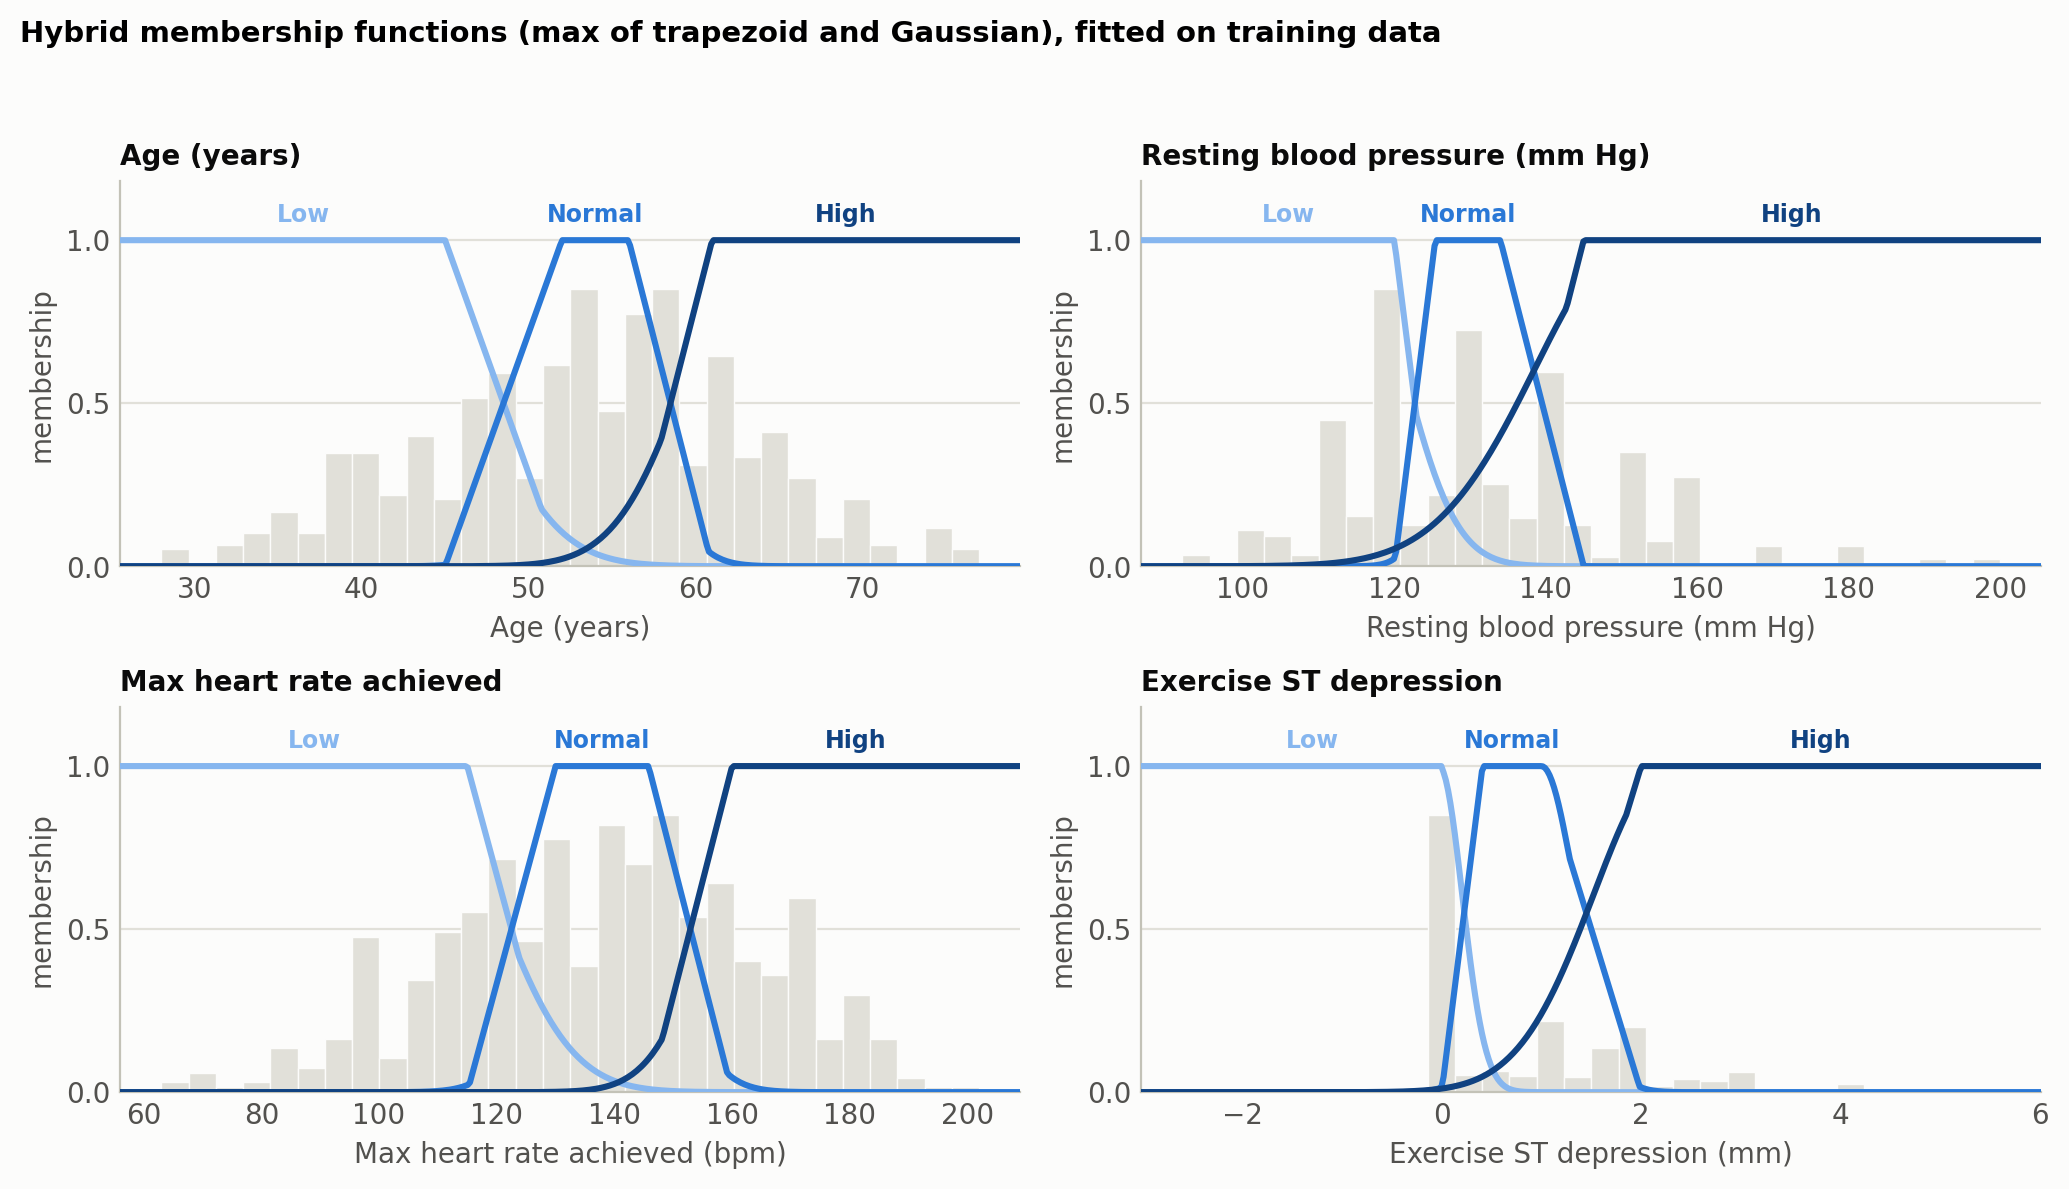

In [2]:
Image("../figures/04_membership_overview.png", width=900)

**The rule base** (phase 5): 31 rules of the form *IF attribute is term THEN class shares are …*, learned as the membership-weighted class share of training patients in that term. It fits on one page and reads like clinical common sense.

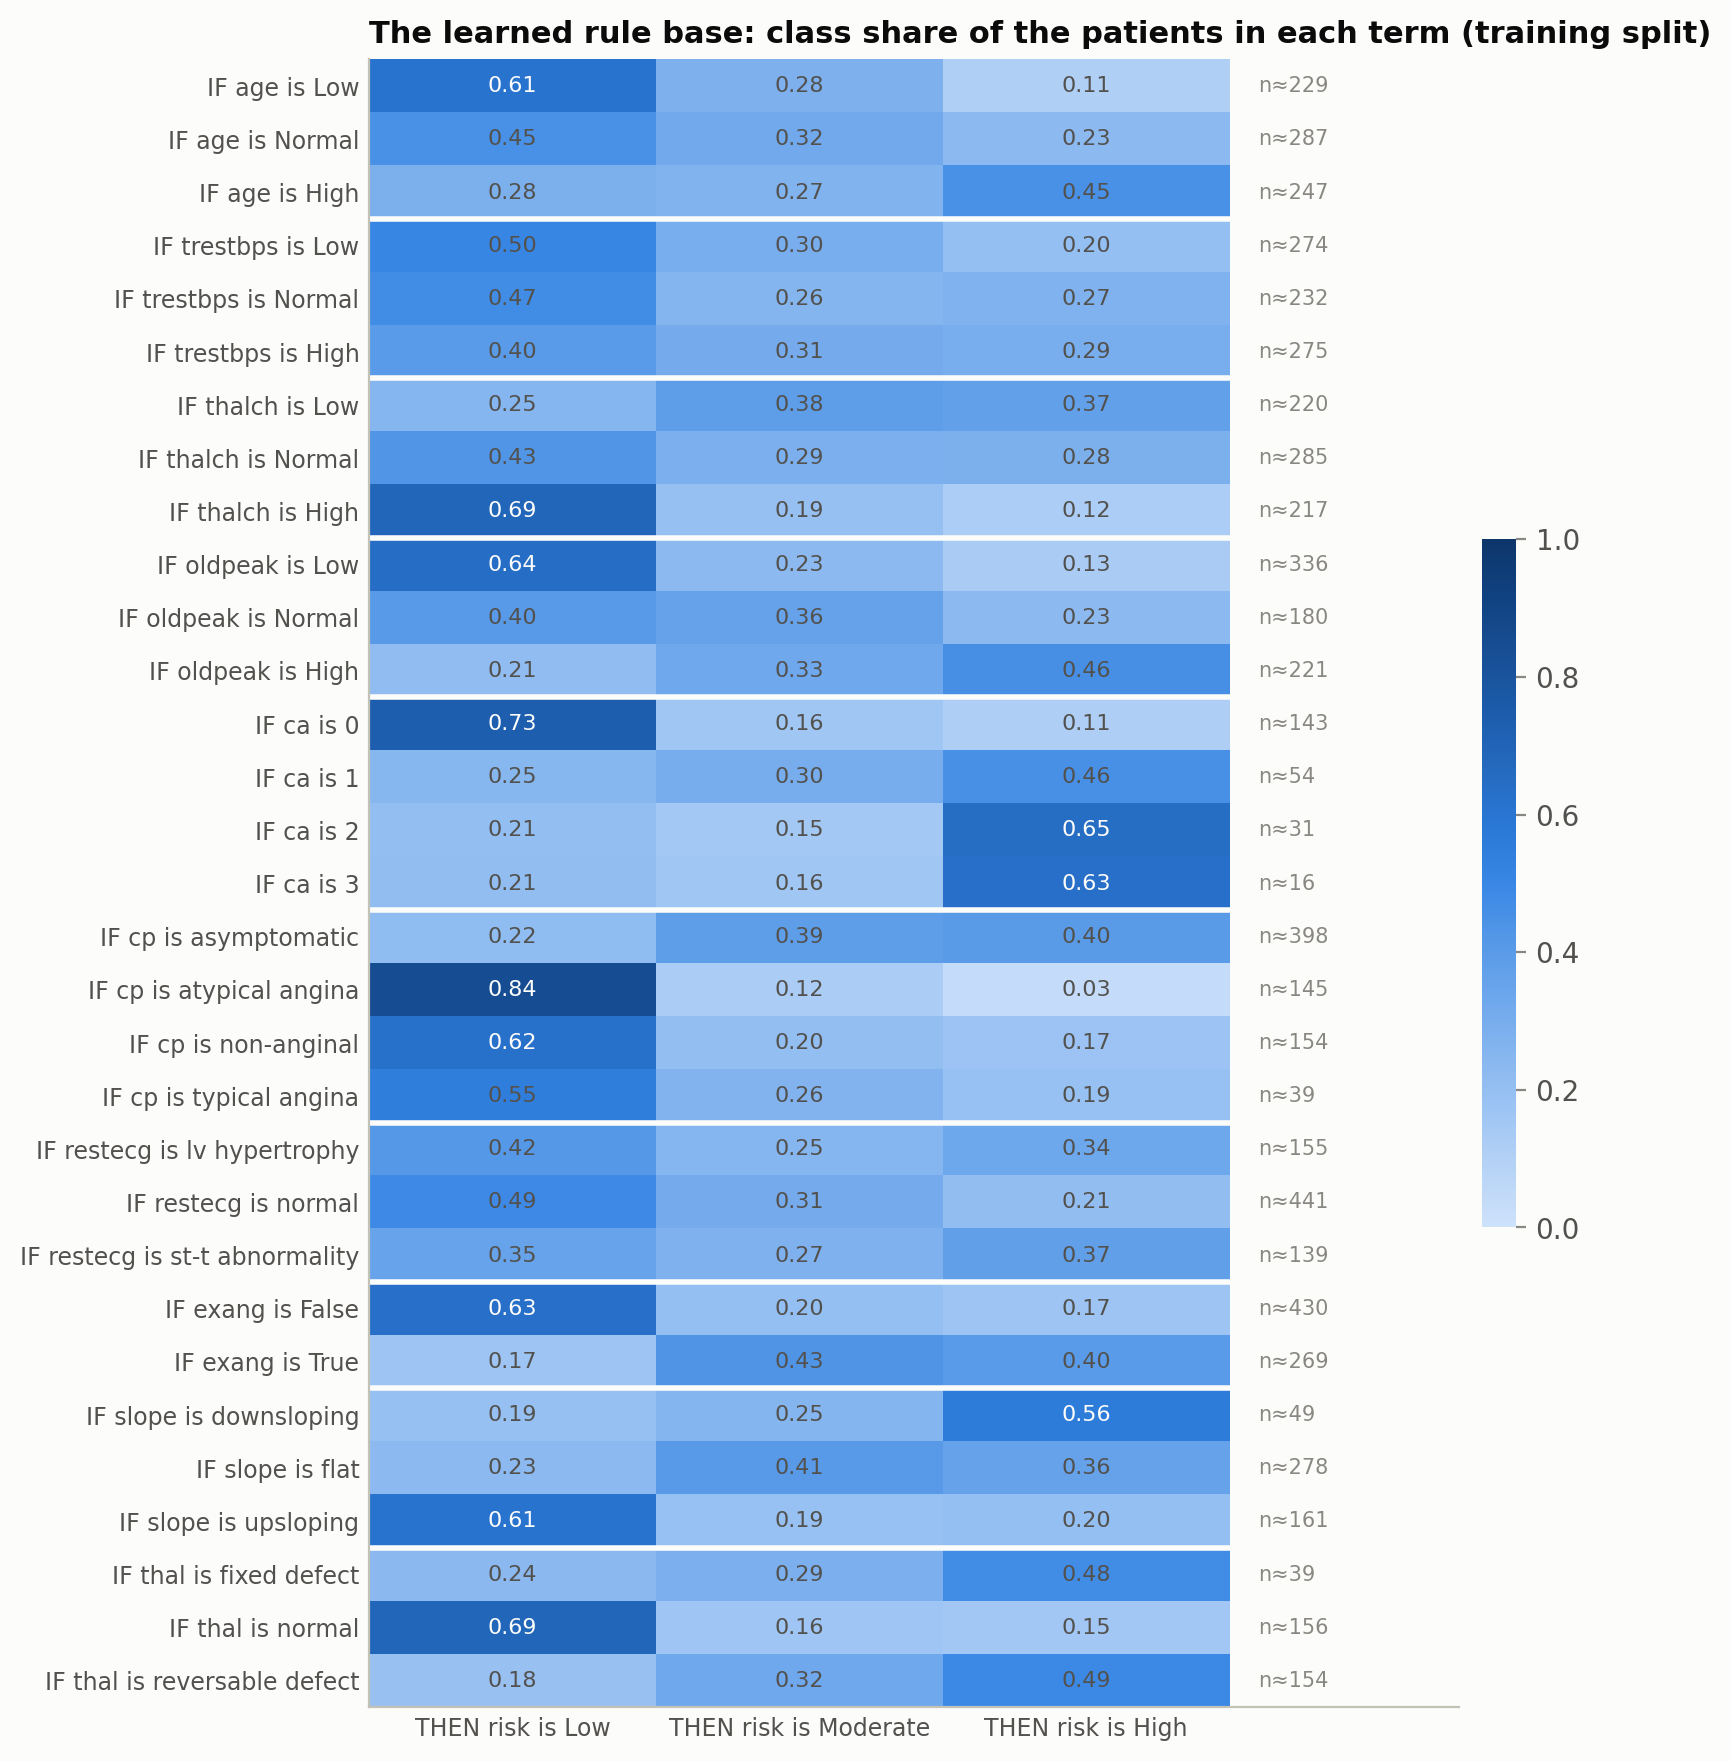

In [3]:
Image("../figures/05_rules.png", width=720)

**Attribute weights**: how much better than guessing each single-attribute model is, on an inner CV of the training split. Resting blood pressure earns zero.

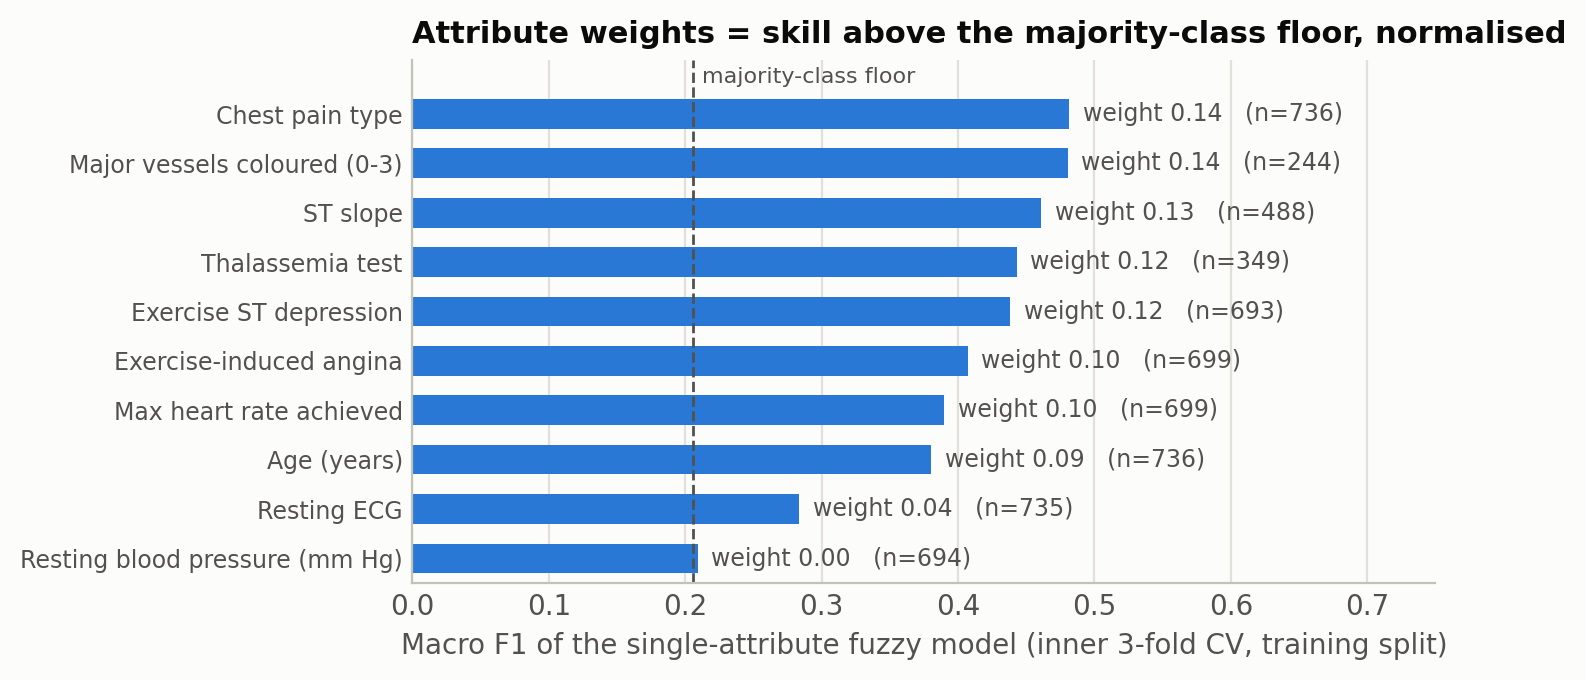

In [4]:
Image("../figures/05_attribute_weights.png", width=660)

**One patient, end to end**: fired terms with memberships, each attribute's contribution scaled by its weight, the combined scores, the clipped output sets, the centroid and the decision.

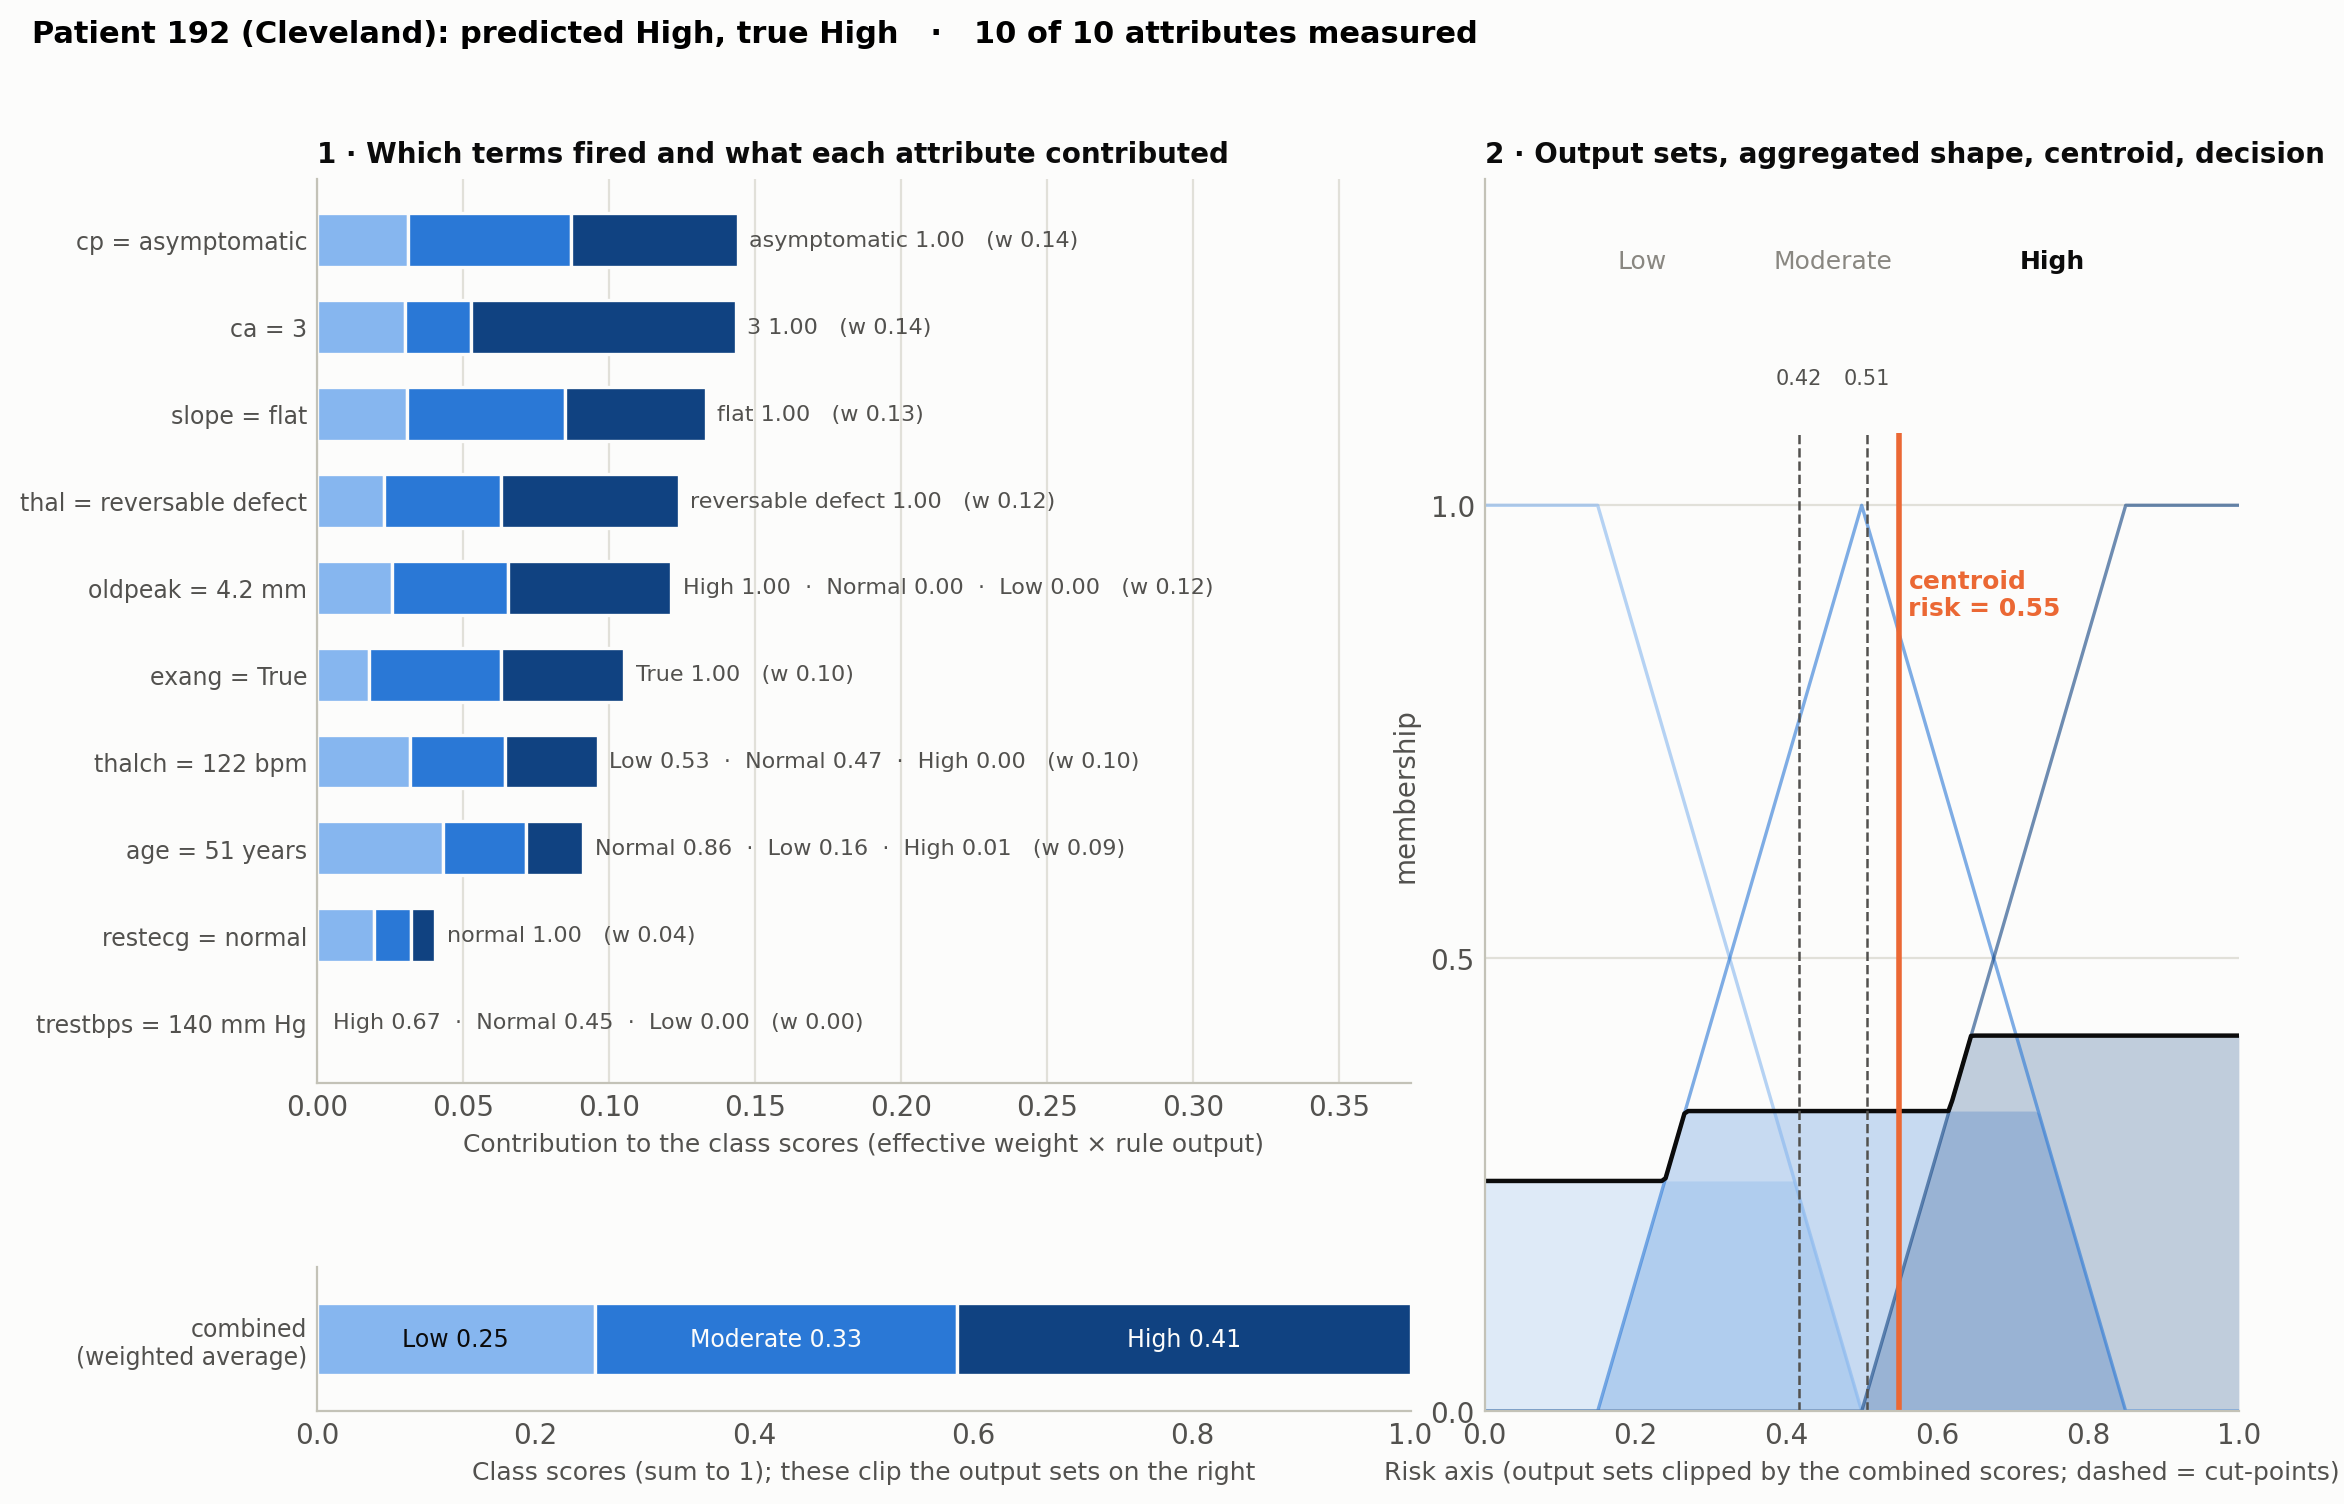

In [5]:
Image("../figures/05_explain_patient_complete.png", width=980)

And a patient whose fluoroscopy and thalassemia test were never done: those attributes are skipped and the measured ones carry the full weight. Nothing is imputed, so nothing about the source hospital leaks in.

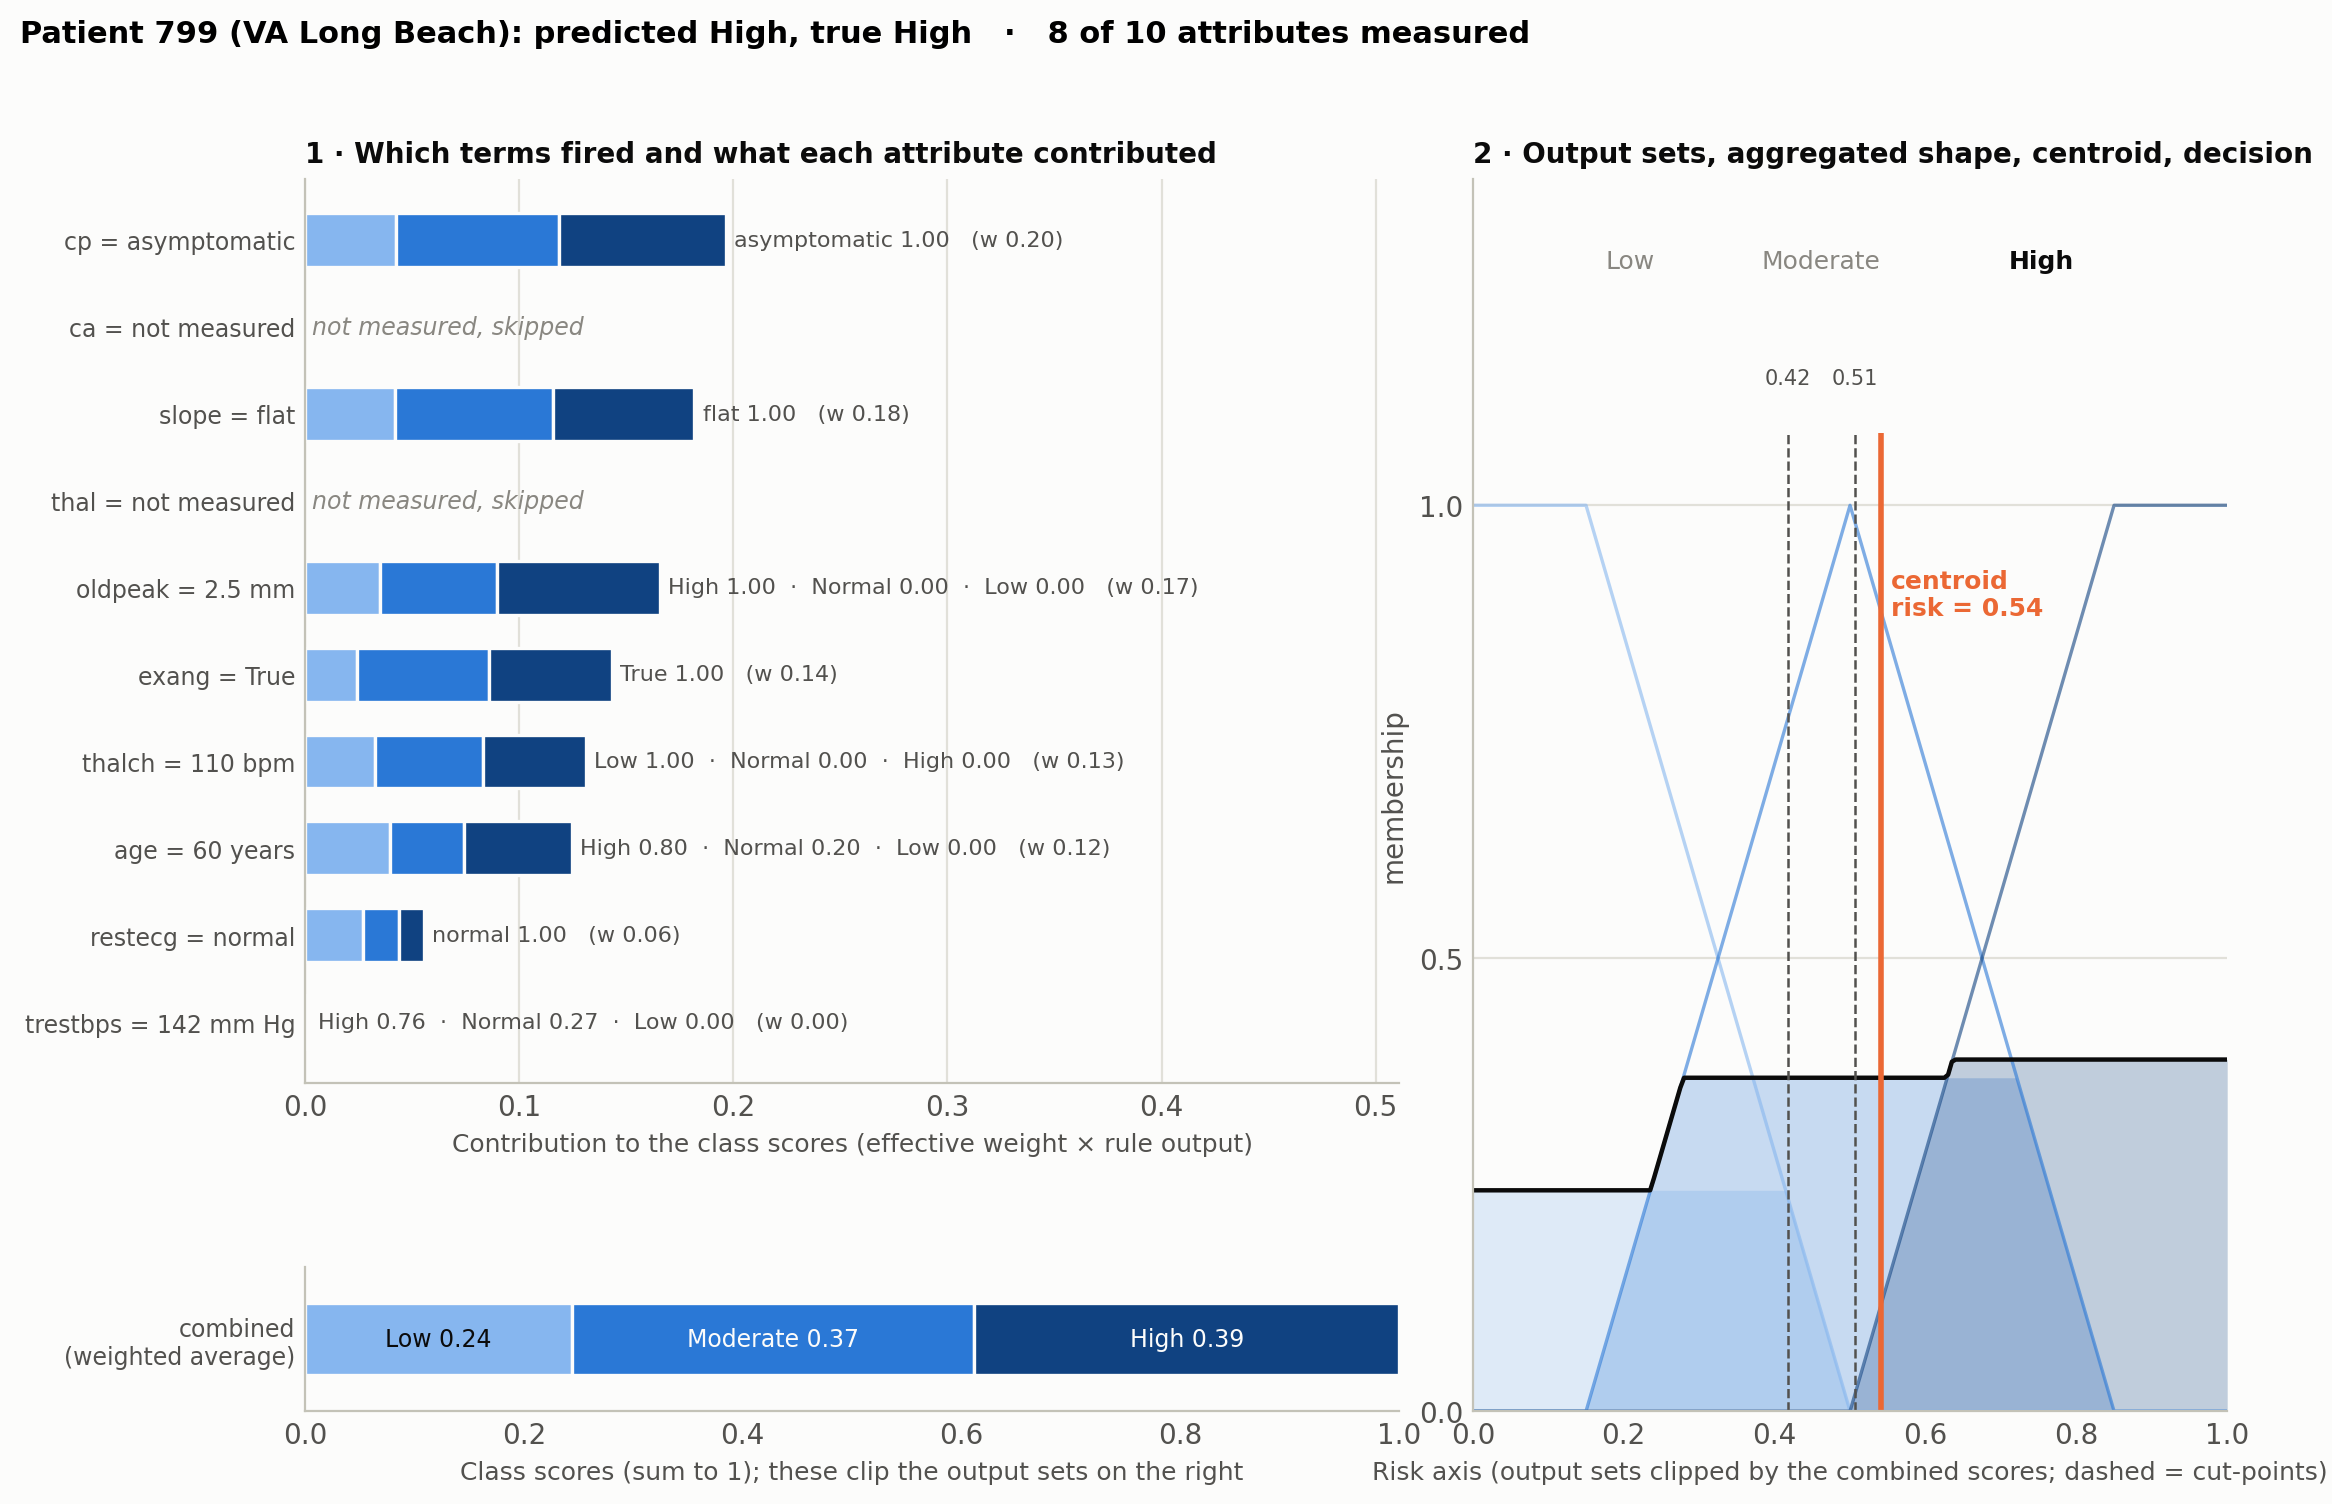

In [6]:
Image("../figures/05_explain_patient_missing.png", width=980)

## 2. The numbers, with uncertainty

In [7]:
cols = ["cv_macro_f1_mean", "cv_macro_f1_sd", "test_macro_f1", "test_macro_f1_lo", "test_macro_f1_hi",
        "test_accuracy", "test_accuracy_lo", "test_accuracy_hi", "cv_mean_inside_test_ci"]
summary[cols].round(3)

,cv_macro_f1_mean,cv_macro_f1_sd,test_macro_f1,test_macro_f1_lo,test_macro_f1_hi,test_accuracy,test_accuracy_lo,test_accuracy_hi,cv_mean_inside_test_ci
model,,,,,,,,,
majority_class,0.206,0.001,0.206,0.182,0.229,0.446,0.375,0.522,True
logistic_regression,0.619,0.045,0.613,0.539,0.676,0.647,0.576,0.712,True
random_forest,0.629,0.048,0.618,0.541,0.686,0.652,0.582,0.723,True
mlp,0.605,0.040,0.562,0.491,0.631,0.609,0.538,0.679,True
hybrid_fuzzy,0.581,0.027,0.496,0.427,0.565,0.516,0.446,0.592,False
hybrid_fuzzy_pairs,0.579,0.038,0.541,0.471,0.608,0.582,0.511,0.652,True


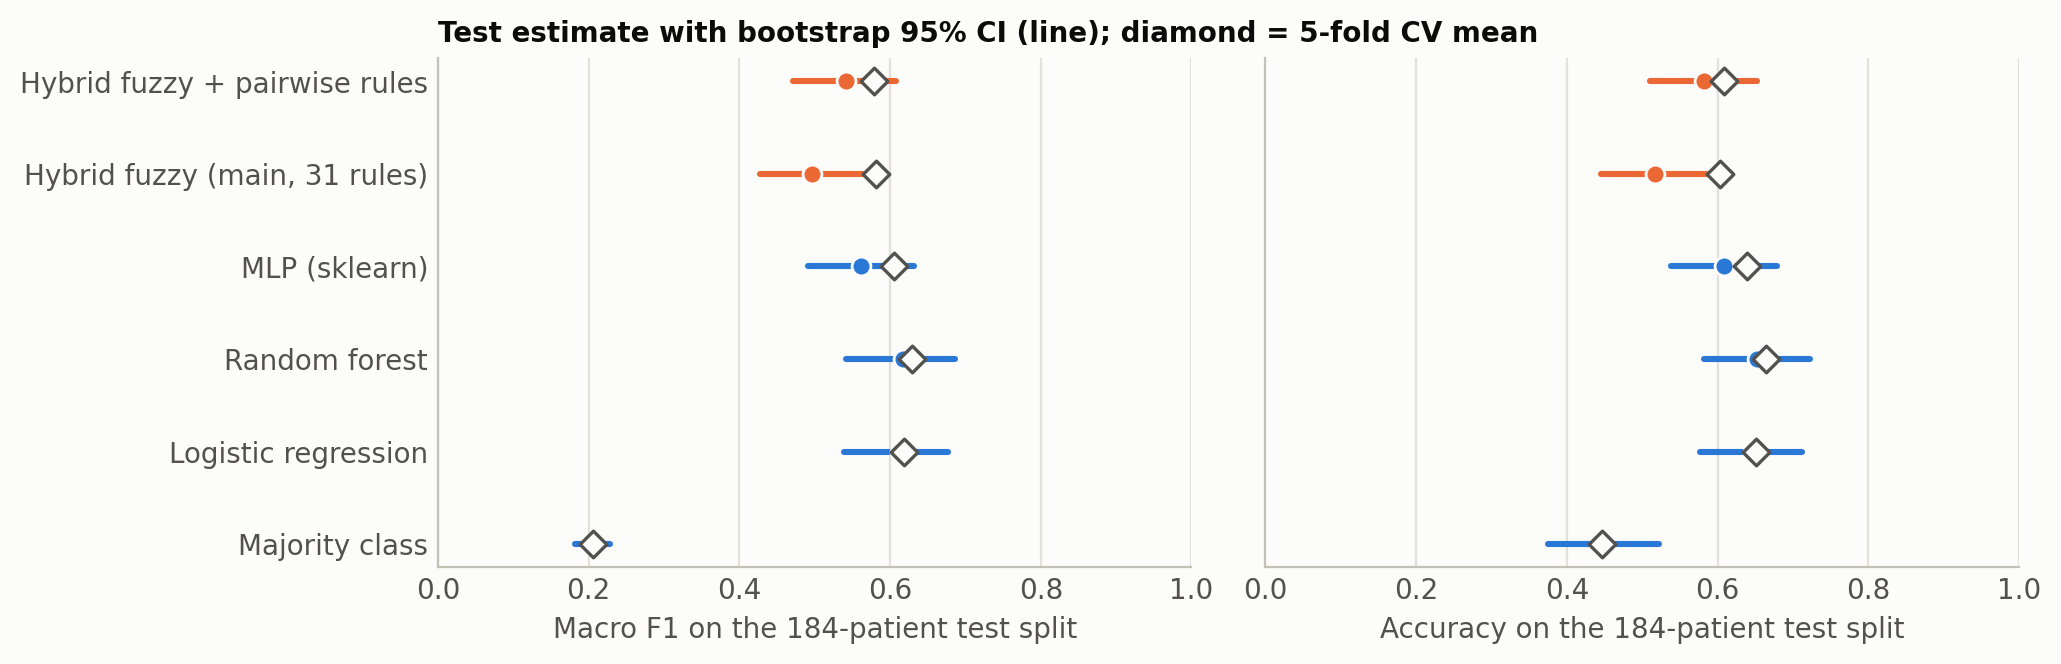

In [8]:
Image("../figures/06_test_ci.png", width=940)

In [9]:
pd.read_csv(R + "06_paired_diff_vs_rf.csv").round(3)

,model,vs,metric,difference,ci_low,ci_high
0,majority_class,random_forest,accuracy,-0.207,-0.293,-0.125
1,majority_class,random_forest,macro_f1,-0.412,-0.488,-0.333
2,logistic_regression,random_forest,accuracy,-0.005,-0.060,0.054
3,logistic_regression,random_forest,macro_f1,-0.005,-0.070,0.061
4,mlp,random_forest,accuracy,-0.043,-0.109,0.022
5,mlp,random_forest,macro_f1,-0.056,-0.129,0.013
6,hybrid_fuzzy,random_forest,accuracy,-0.136,-0.212,-0.065
7,hybrid_fuzzy,random_forest,macro_f1,-0.122,-0.202,-0.044
8,hybrid_fuzzy_pairs,random_forest,accuracy,-0.071,-0.130,-0.005
9,hybrid_fuzzy_pairs,random_forest,macro_f1,-0.077,-0.146,-0.005


How to read this:

- **Baselines.** Logistic regression, random forest and the MLP are indistinguishable from each other: their paired differences against the random forest all include zero.
- **Main fuzzy model (31 rules).** CV macro F1 0.58 ± 0.03, test 0.50 with CI [0.43, 0.57]. It is the only model whose CV mean lies *outside* its own test CI, and its paired difference to the random forest, −0.12 macro F1 with CI [−0.20, −0.04], excludes zero. So the CV-to-test drop is not noise. The most likely cause is the cut-points: two thresholds chosen on inner-CV risk scores of a compressed axis (nearly all patients between 0.33 and 0.57) are fragile, and a small shift in the test distribution moves many patients across them.
- **Pairwise variant (60 rules).** Ties the main model on CV macro F1 (0.579 vs 0.581, the pre-agreed selection criterion, so it did not become the main model), widens the risk axis a little (out-of-fold sd 0.076 vs 0.067), and lands at 0.54 on the test split with its CV mean inside its CI. Its difference to the random forest, −0.08 with CI [−0.15, −0.005], is marginal. Its better test score is reported but was not used to choose it.
- **Moderate class.** Out-of-fold Moderate F1 is about 0.47 for every model including both fuzzy variants; on the test split the pairwise variant reaches 0.45 and the main model 0.35. The ordinal middle class is where all models struggle.

In [10]:
pd.read_csv(R + "06_fuzzy_variants.csv", index_col=0)

,n_rules,pairs,oof_risk_sd,oof_risk_iqr,cutpoints
model,,,,,
hybrid_fuzzy,31,[],0.067012,0.119481,"(0.417, 0.506)"
hybrid_fuzzy_pairs,60,"[('ca', 'cp'), ('ca', 'slope'), ('cp', 'slope')]",0.076430,0.134590,"(0.44, 0.533)"


The pairwise rule base, for the record (still one page):

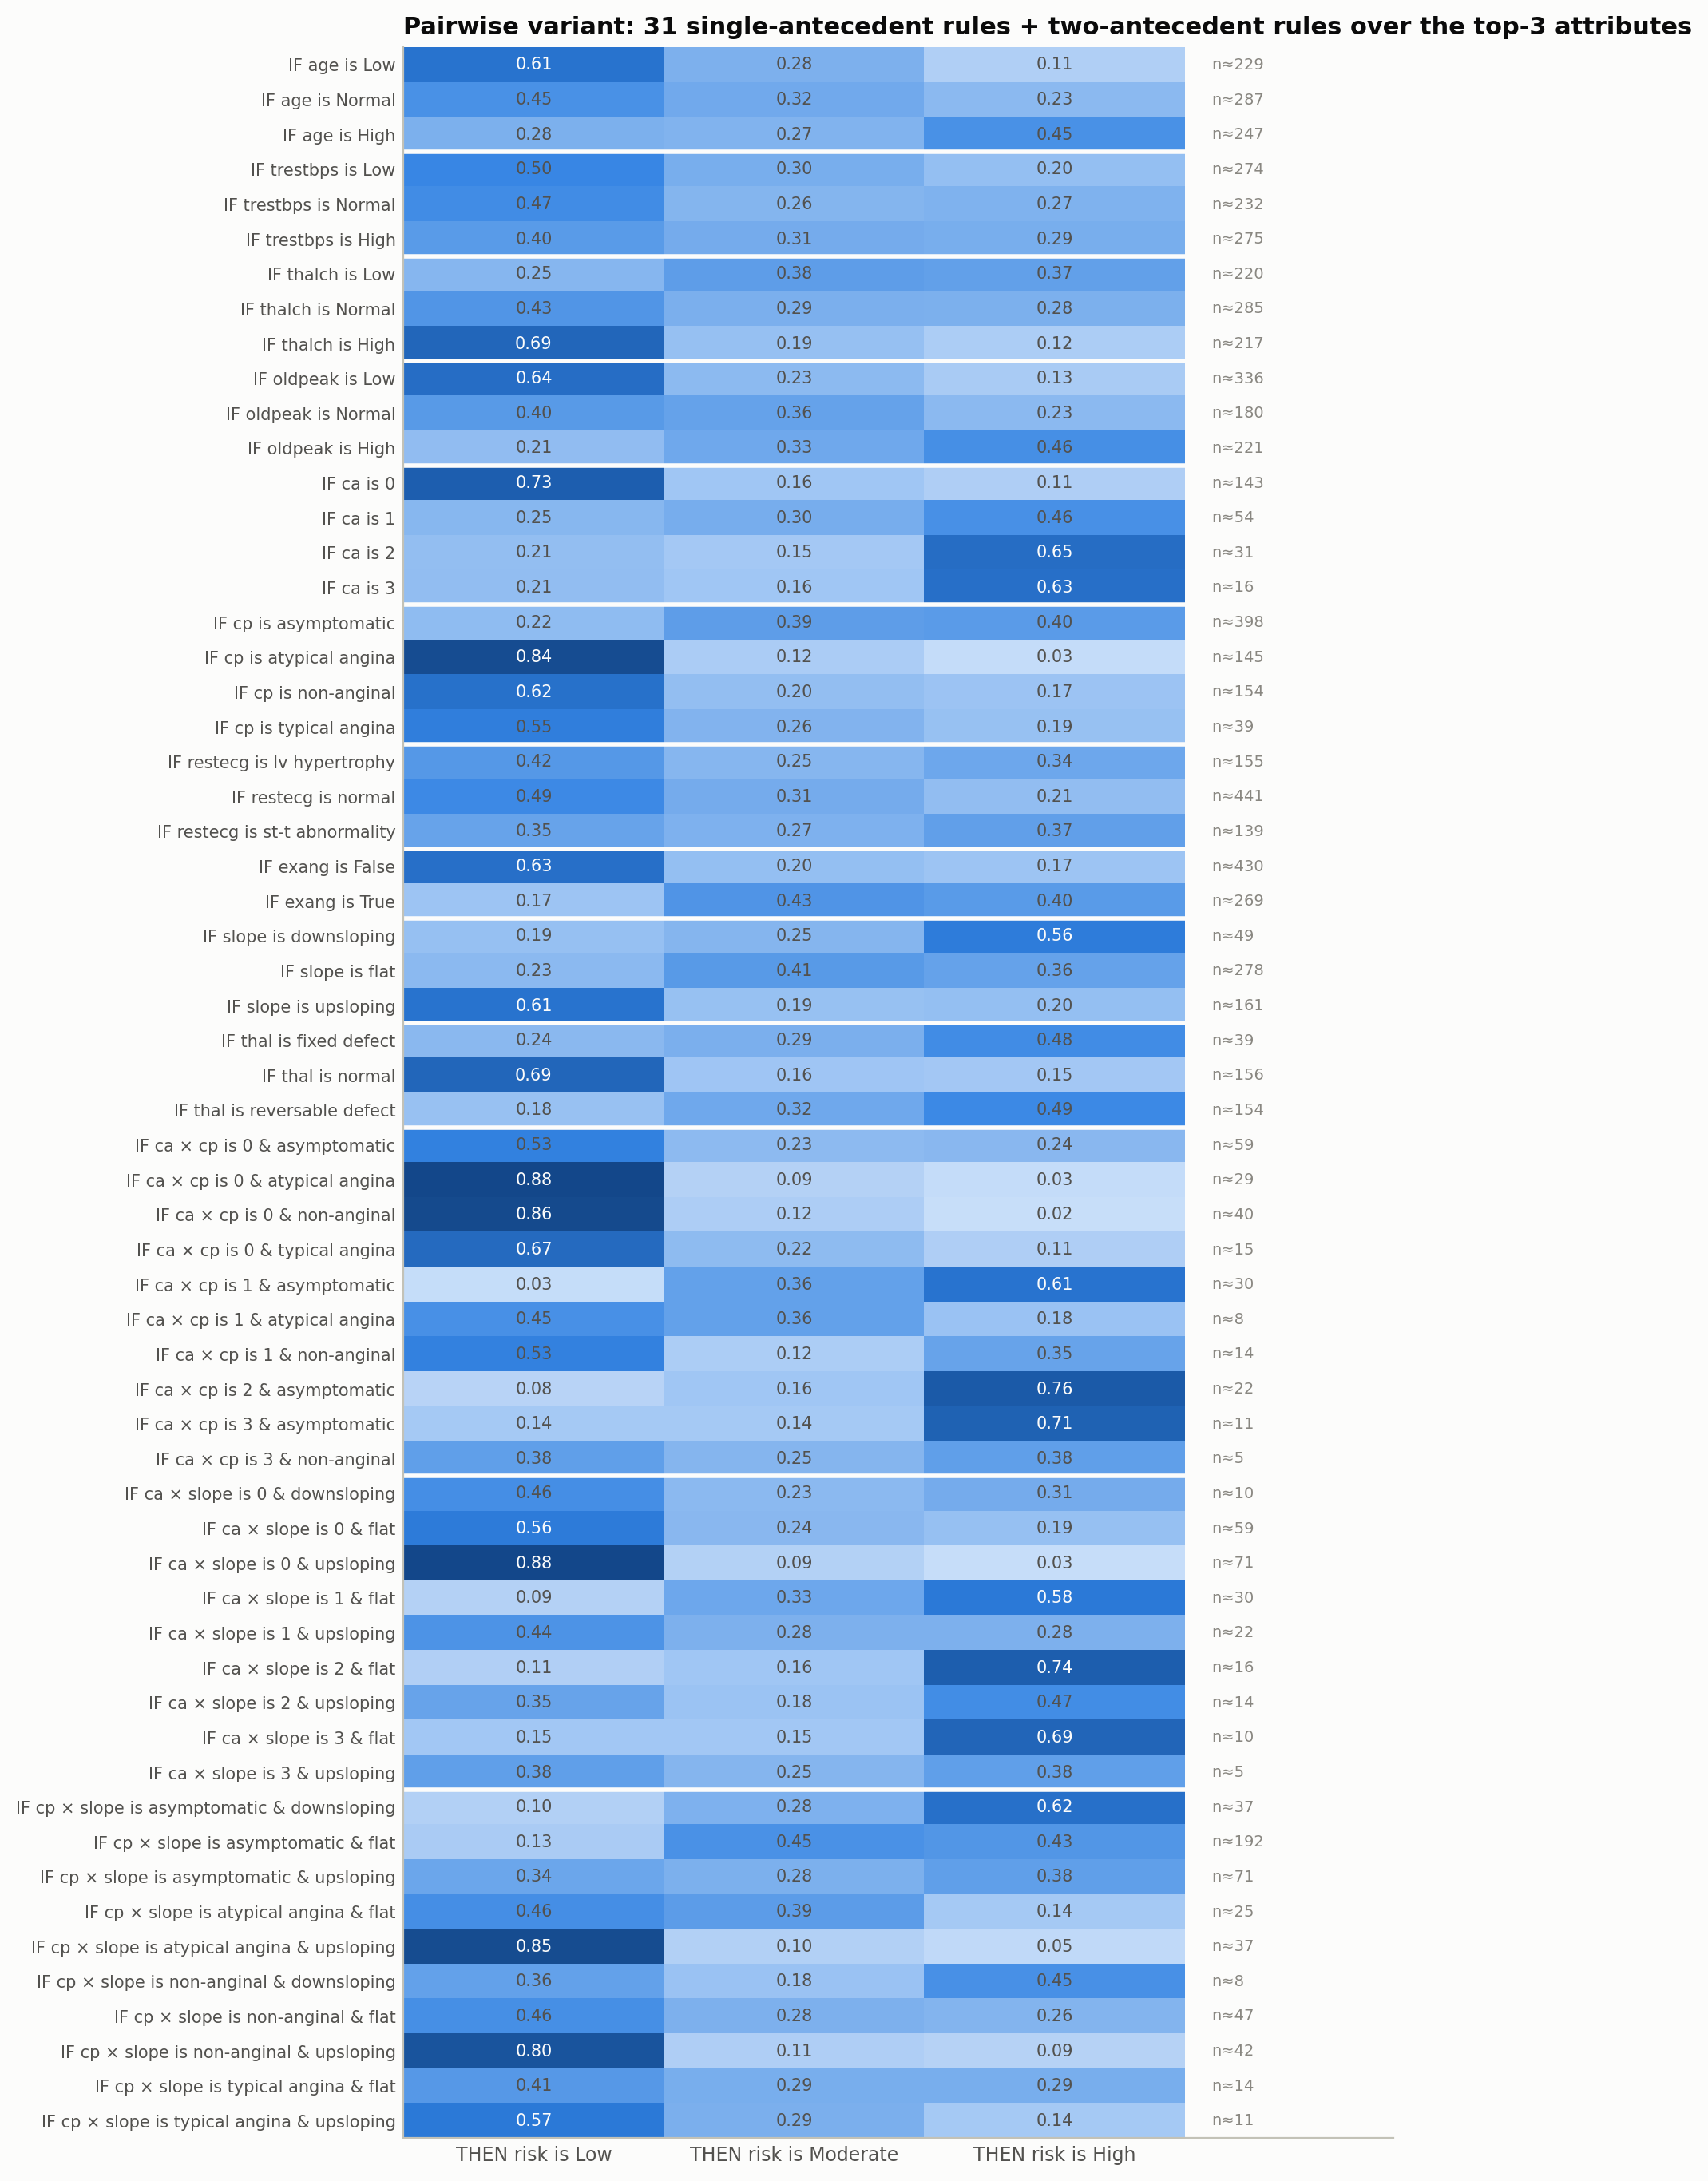

In [11]:
Image("../figures/06_rules_pairs.png", width=760)

## 3. Per-hospital view

In [12]:
site = pd.read_csv(R + "06_per_site.csv")
site.pivot(index="site", columns="model", values="macro_f1").round(3)

model,hybrid_fuzzy,hybrid_fuzzy_pairs,logistic_regression,majority_class,mlp,random_forest
site,,,,,,
Cleveland,0.561,0.558,0.578,0.232,0.557,0.556
Hungary,0.739,0.747,0.764,0.397,0.753,0.756
Switzerland,0.390,0.389,0.387,0.033,0.387,0.399
VA Long Beach,0.471,0.463,0.503,0.127,0.495,0.534


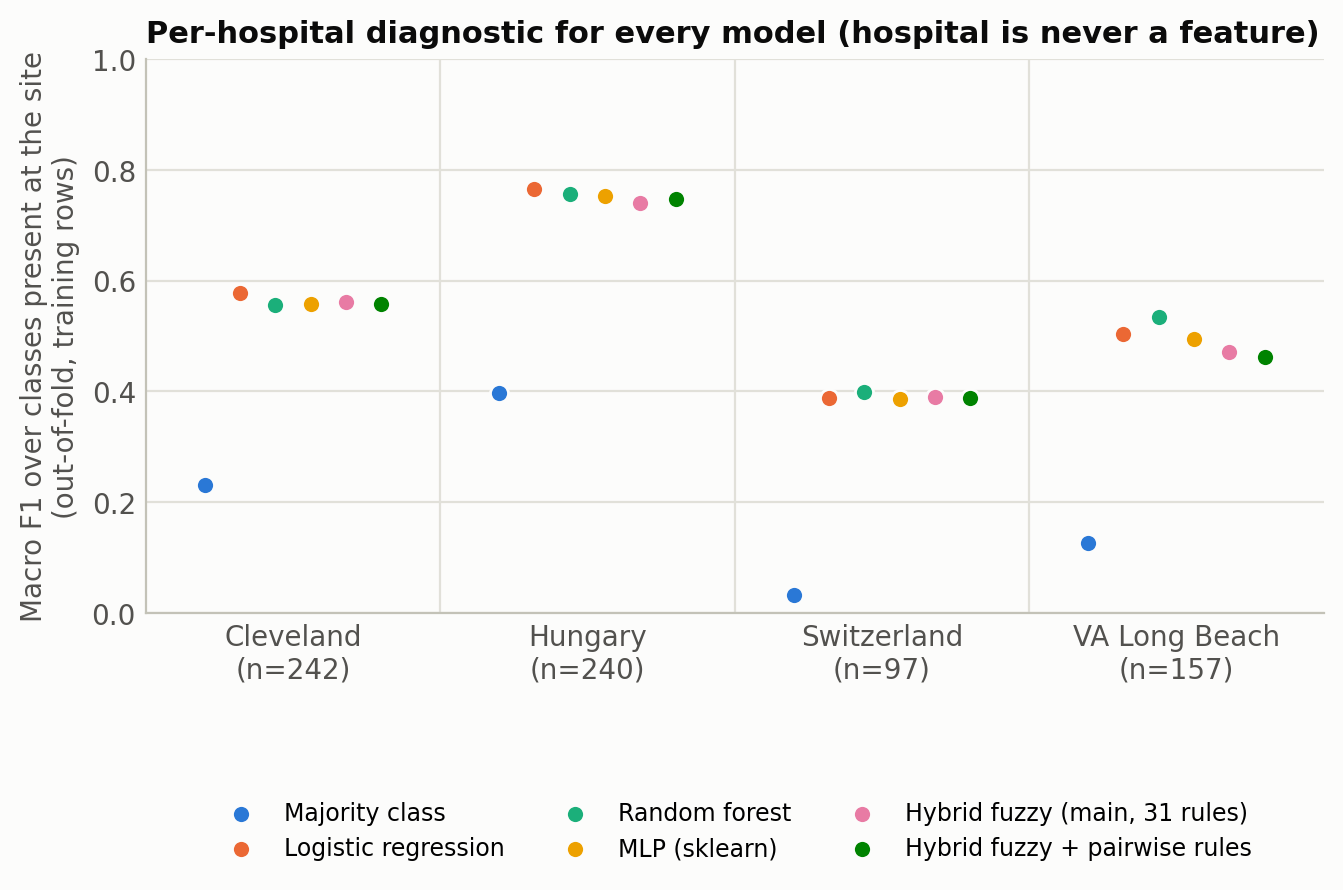

In [13]:
Image("../figures/06_per_site_all.png", width=760)

On out-of-fold training predictions the fuzzy models are on par with the baselines at Cleveland, Hungary and Switzerland and a little behind at VA Long Beach. Switzerland is hardest for everyone (no cholesterol, almost no fluoroscopy, 93% diseased). The fuzzy model gets its Swiss result without any imputed values: those patients are scored on what was measured.

## 4. Limitations

- **Accuracy.** The patented structure (single-antecedent rules, weighted average, centroid) is behind the conventional baselines by about 0.05 macro F1 under CV and more on the held-out split. Rules on one attribute at a time cannot express interactions; the pairwise layer recovers some of that but not all.
- **Cut-point fragility.** A compressed risk axis makes the two thresholds sensitive to distribution shift. Calibrating the combined scores before defuzzification, or learning cut-points with a regulariser, is the obvious next step.
- **Hospital-linked attributes.** `ca`, `thal` and `slope` are measured mostly at Cleveland and carry the highest weights. The fuzzy model does not impute them, but their *presence* still differs by site. The ablation in the README backlog (drop all three) would quantify the dependence.
- **Labels.** The Low / Moderate / High mapping from `num` is this project's choice; the patent's class supports do not match any grouping of `num`, so its reported figures are not comparable.
- **Data.** 920 patients from four hospitals collected decades ago; nothing here is validated for clinical use.